In [1]:
# ============================================================
# CELL 1 — Imports and configuration
# ============================================================
# Natural Gas Storage Tracker
# Source : EIA API v2
# Release : Every Thursday 10:30am EST
# Series : Weekly Working gas in underground storage
# Regions : US Total, East, Midwest, Mountain, Pacific,
#           South Central (total, salt caverns, nonsalt)
# ─────────────────────────────────────────────────────────────

# Standard library
import sys
import os
from pathlib import Path
import datetime as dt

# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# HTTP requests
import requests

# Display settings
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.style.use("seaborn-v0_8-darkgrid")

# ── Path setup ───────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
import config

# ── Constants ────────────────────────────────────────────────
API_KEY = config.EIA_API_KEY
BASE_URL = "https://api.eia.gov/v2"

CHART_DIR = PROJECT_ROOT / "charts"
DATA_DIR = PROJECT_ROOT / "data"

# ── Date ranges ───────────────────────────────────────────────
# Two separate windows:
#   YEARS_HISTORY    : seasonal range chart (recent regime)
#   YEARS_PERCENTILE : percentile rank (longer history)
YEARS_HISTORY    = 5
YEARS_PERCENTILE = 10   # EIA gas storage data goes back to ~2010

END_DATE          = dt.date.today()
START_DATE        = END_DATE - dt.timedelta(
    days=365 * YEARS_HISTORY + 30
)
START_DATE_PCTILE = END_DATE - dt.timedelta(
    days=365 * YEARS_PERCENTILE + 30
)

print("=" * 55)
print("Tool 3 — Natural Gas Storage Tracker")
print("=" * 55)
print(f"Project root : {PROJECT_ROOT}")
print(f"API key      : {API_KEY[:6]}{'*' * 20} (masked)")
print(f"Date range   : {START_DATE} -> {END_DATE}")
print(f"History      : {YEARS_HISTORY} years of weekly data")
print(f"Percentile   : {YEARS_PERCENTILE} years "
      f"({START_DATE_PCTILE.year}-present)")
print("=" * 55)

Tool 3 — Natural Gas Storage Tracker
Project root : c:\Users\mackt\Python Projects\oil_gas_tools
API key      : K8wjSh******************** (masked)
Date range   : 2021-09-11 -> 2026-10-10
History      : 5 years of weekly data
Percentile   : 10 years (2016-present)


In [2]:
# ============================================================
# CELL 2 — EIA API fetch function
# ============================================================
# Identical to Tool 1 Cell 2 — generic EIA v2 fetcher.
# Retyped here so this notebook is fully self-contained.
# ─────────────────────────────────────────────────────────────

def fetch_eia_series(
        route: str,
        facets: dict,
        start: str,
        end: str,
        api_key: str,
        frequency: str = "weekly",
        value_col: str = "value",
        max_rows: int = 5000,
) -> pd.DataFrame:
    """
    Fetch a time series from the EIA API v2 and return a DataFrame.

    Parameters
    ----------
    route     : API route after base URL, e.g. '/natural-gas/stor/wkly/data/'
    facets    : filter dict, e.g. {'duoarea': ['NUS'], 'process': ['SAT']}
    start     : start date string 'YYYY-MM-DD'
    end       : end date string 'YYYY-MM-DD'
    api_key   : EIA API key
    frequency : data frequency — 'weekly', 'monthly', 'annual'
    value_col : name for the value column in the output DataFrame
    max_rows  : max rows per request (EIA cap is 5000)

    Returns
    -------
    pd.DataFrame with columns: date, {value_col}
    Sorted ascending by date, date as datetime64, NaNs dropped.
    """
    # ── Build request parameters ─────────────────────────────
    params = {
        "api_key" : api_key,
        "frequency" : frequency,
        "data[0]" : "value",
        "start" : start,
        "end" : end,
        "sort[0][column]" : "period",
        "sort[0][direction]" : "asc",
        "length" : max_rows,
    }

    for facet_name, facet_values in facets.items():
        for val in facet_values:
            params[f"facets[{facet_name}][]"] = val

    url = f"{BASE_URL}{route}"

    # ── Make the request ─────────────────────────────────────
    try:
        response = requests.get(url, params=params, timeout=30)
        response.raise_for_status()
    except requests.exceptions.Timeout:
        raise RuntimeError(
            "EIA API request timed out. \n"
            "Check https://api.eia.gov - may be under maintenance."
        )
    except requests.exceptions.HTTPError as e:
        raise RuntimeError(f"EIA API HTTP error: {e}\nURL: {response.url}")
    except requests.exceptions.RequestException as e:
        raise RuntimeError(f"EIA API request failed: {e}")
    
    # ── Parse response ───────────────────────────────────────
    payload = response.json()

    if "error" in payload:
        raise RuntimeError(f"EIA API returned an error: {payload['error']}")
    
    data = payload.get("response", {}).get("data", [])

    if not data:
        raise ValueError(
            f"EIA API returned no data for this request.\n"
            f"Route: {route}\nFacets: {facets}\n"
            f"Date range: {start} -> {end}\n"
            f"Check that your facet codes are correct."
        )
    
    # ── Build DataFrame ──────────────────────────────────────
    df = pd.DataFrame(data)
    df["date"] = pd.to_datetime(df["period"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = df[["date", "value"]].copy()
    df = df.rename(columns={"value": value_col})
    df = df.sort_values("date").reset_index(drop=True)

    n_before = len(df)
    df = df.dropna(subset=[value_col])
    n_dropped = n_before - len(df)
    if n_dropped > 0:
        print(f" !! Dropped {n_dropped} rows with missing values.")

    return df

# ── Smoke test ───────────────────────────────────────────────
print("=" * 55)
print("Cell 2 loaded — fetch_eia_series() ready")
print(f"Base URL : {BASE_URL}")
print(f"Timeout  : 30 seconds per request")
print(f"Max rows : 5,000 per request")
print("=" * 55)

Cell 2 loaded — fetch_eia_series() ready
Base URL : https://api.eia.gov/v2
Timeout  : 30 seconds per request
Max rows : 5,000 per request


In [3]:
# ============================================================
# CELL 3 — Pull gas storage data from EIA
# ============================================================
# EIA Natural Gas Weekly Storage series
# Route   : /natural-gas/stor/wkly/data/
#
# duoarea codes (updated — EIA changed these):
#   R48 = Lower 48 States (formerly NUS / US Total)
#   R31 = East region     (formerly R30)
#   R32 = Midwest region  (formerly R20)
#   R33 = South Central   (formerly R10)
#   R34 = Mountain        (formerly R40)
#   R35 = Pacific         (formerly R50)
#
# process : SWO = total working gas (formerly SAT)
# Units   : Bcf — no conversion needed
# ─────────────────────────────────────────────────────────────

ROUTE = "/natural-gas/stor/wkly/data/"
START = START_DATE.strftime("%Y-%m-%d")
END   = END_DATE.strftime("%Y-%m-%d")

# Region name -> EIA duoarea code (verified April 2026)
regions = {
    "us_total"   : "R48",
    "east"       : "R31",
    "midwest"    : "R32",
    "south_total": "R33",
    "mountain"   : "R34",
    "pacific"    : "R35",
}

print("Fetching EIA natural gas storage data...")
print(f"  Date range : {START} -> {END}")
print()

# ── Fetch each region ────────────────────────────────────────
frames = {}
for name, code in regions.items():
    print(f"  [{name}] ({code})...", end=" ")
    df_r = fetch_eia_series(
        route     = ROUTE,
        facets    = {"duoarea": [code], "process": ["SWO"]},
        start     = START,
        end       = END,
        api_key   = API_KEY,
        value_col = name,
    )
    frames[name] = df_r
    print(f"OK  ({len(df_r)} weeks)")

# ── Merge all regions onto Lower 48 total as spine ───────────
df = frames["us_total"].copy()

for name, frame in frames.items():
    if name == "us_total":
        continue
    df = df.merge(frame, on="date", how="left")

df = df.sort_values("date").reset_index(drop=True)

# ── Add calendar columns for seasonal analysis ───────────────
df["year"]    = df["date"].dt.year
df["week"]    = df["date"].dt.isocalendar().week.astype(int)
df["month"]   = df["date"].dt.month
df["week_id"] = df["week"].clip(upper=52)

# ── Preview ──────────────────────────────────────────────────
print()
print("=" * 55)
print("Data pull complete")
print("=" * 55)
print(f"Rows       : {len(df)} weekly observations")
print(f"Date range : {df['date'].min().date()}  ->  "
      f"{df['date'].max().date()}")
print(f"Lower 48   : {df['us_total'].min():.0f} – "
      f"{df['us_total'].max():.0f} Bcf")
print(f"S. Central : {df['south_total'].min():.0f} – "
      f"{df['south_total'].max():.0f} Bcf")
print("=" * 55)
print()
print(df[["date","us_total","east","midwest",
          "south_total","mountain","pacific"]].tail(6).to_string(index=False))

# ── Pull extended history for percentile calculation ──────────
# Separate pull — more years = more data points per week_id
# = finer percentile granularity
print()
print("Pulling extended history for percentile calculation...")

START_PCTILE = START_DATE_PCTILE.strftime("%Y-%m-%d")

df_us_pctile = fetch_eia_series(
    route     = ROUTE,
    facets    = {"duoarea": ["R48"], "process": ["SWO"]},
    start     = START_PCTILE,
    end       = END,
    api_key   = API_KEY,
    value_col = "us_total",
)
df_us_pctile["year"]    = df_us_pctile["date"].dt.year
df_us_pctile["week"]    = (df_us_pctile["date"]
                           .dt.isocalendar().week.astype(int))
df_us_pctile["week_id"] = df_us_pctile["week"].clip(upper=52)

df_sc_pctile = fetch_eia_series(
    route     = ROUTE,
    facets    = {"duoarea": ["R33"], "process": ["SWO"]},
    start     = START_PCTILE,
    end       = END,
    api_key   = API_KEY,
    value_col = "south_total",
)
df_sc_pctile["year"]    = df_sc_pctile["date"].dt.year
df_sc_pctile["week"]    = (df_sc_pctile["date"]
                           .dt.isocalendar().week.astype(int))
df_sc_pctile["week_id"] = df_sc_pctile["week"].clip(upper=52)

# Historical only — exclude current year
CURRENT_YEAR = df["date"].dt.year.max()
df_us_pctile_hist = df_us_pctile[
    df_us_pctile["year"] < CURRENT_YEAR
].copy()
df_sc_pctile_hist = df_sc_pctile[
    df_sc_pctile["year"] < CURRENT_YEAR
].copy()

n_us_pctile_pts = len(
    df_us_pctile_hist[
        df_us_pctile_hist["week_id"] == current_week
    ]
) if "current_week" in dir() else "?"

print(f"  US pctile history  : {len(df_us_pctile_hist)} weeks "
      f"({df_us_pctile_hist['year'].min()}-"
      f"{df_us_pctile_hist['year'].max()})")
print(f"  SC pctile history  : {len(df_sc_pctile_hist)} weeks "
      f"({df_sc_pctile_hist['year'].min()}-"
      f"{df_sc_pctile_hist['year'].max()})")

Fetching EIA natural gas storage data...
  Date range : 2021-09-11 -> 2026-10-10

  [us_total] (R48)... OK  (264 weeks)
  [east] (R31)... OK  (264 weeks)
  [midwest] (R32)... OK  (264 weeks)
  [south_total] (R33)... OK  (264 weeks)
  [mountain] (R34)... OK  (264 weeks)
  [pacific] (R35)... OK  (264 weeks)

Data pull complete
Rows       : 264 weekly observations
Date range : 2021-09-17  ->  2026-10-02
Lower 48   : 1382 – 3972 Bcf
S. Central : 559 – 1345 Bcf

      date  us_total  east  midwest  south_total  mountain  pacific
2026-08-28      3214   753      890         1051       236      285
2026-09-04      3254   773      908         1044       239      290
2026-09-11      3298   795      934         1039       241      289
2026-09-18      3351   815      959         1041       244      292
2026-09-25      3415   840      984         1048       248      295
2026-10-02      3500   862     1010         1076       253      299

Pulling extended history for percentile calculation...
  US p

In [4]:
# ============================================================
# CELL 4 — Validate and split current vs historical
# ============================================================
print("Running data validation...")
print()

# ── 1. Check for duplicate dates ─────────────────────────────
dupes = df[df.duplicated(subset=["date"], keep=False)]
if len(dupes) > 0:
    print(f"!! WARNING: {len(dupes)} duplicate dates found — dropping extras")
    df = df.drop_duplicates(subset=["date"], keep="last")
else:
    print("  No duplicate dates")

# ── 2. Check for gaps in weekly sequence ─────────────────────
df_sorted   = df.sort_values("date").reset_index(drop=True)
date_diffs  = df_sorted["date"].diff().dropna()
expected    = pd.Timedelta(days=7)
gaps        = date_diffs[date_diffs > expected + pd.Timedelta(days=3)]

if len(gaps) > 0:
    print(f"!! WARNING: {len(gaps)} gaps in weekly sequence:")
    for idx, gap in gaps.items():
        print(f"   {df_sorted.loc[idx-1, 'date'].date()} -> "
              f"{df_sorted.loc[idx, 'date'].date()} "
              f"({gap.days} days)")
else:
    print("  No gaps in weekly sequence")

# ── 3. Validate value ranges (Bcf) ───────────────────────────
checks = [
    ("us_total",    1000, 4200, "Bcf"),
    ("east",         200, 1000, "Bcf"),
    ("midwest",      200, 1200, "Bcf"),
    ("south_total",  500, 1400, "Bcf"),
    ("mountain",      50,  320, "Bcf"),
    ("pacific",       60,  650, "Bcf"),
]

for col, lo, hi, unit in checks:
    out = df[(df[col] < lo) | (df[col] > hi)]
    if len(out) > 0:
        print(f"!! WARNING: {len(out)} rows outside "
              f"[{lo}–{hi} {unit}] in {col}")
        print(out[["date", col]])
    else:
        print(f"  {col}: all values in plausible range "
              f"[{lo}–{hi} {unit}]")

# ── 4. Add week_id for seasonal grouping ─────────────────────
# Clip ISO week at 52 for clean grouping
# (week 53 exists in some years — treated as week 52)
df["week_id"] = df["week"].clip(upper=52)

# ── 5. Split current year vs historical ──────────────────────
CURRENT_YEAR = df["date"].dt.year.max()
df_current   = df[df["year"] == CURRENT_YEAR].copy()
df_history   = df[df["year"] <  CURRENT_YEAR].copy()

print()
print("=" * 55)
print("Validation complete")
print("=" * 55)
print(f"Total rows    : {len(df)}")
print(f"Current year  : {CURRENT_YEAR} "
      f"({len(df_current)} weeks so far)")
print(f"Historical    : {df_history['year'].min()} – "
      f"{CURRENT_YEAR - 1} "
      f"({len(df_history)} weeks)")
print(f"Week IDs      : {df['week_id'].min()} – "
      f"{df['week_id'].max()}")
print("=" * 55)

Running data validation...

  No duplicate dates
  No gaps in weekly sequence
  us_total: all values in plausible range [1000–4200 Bcf]
  east: all values in plausible range [200–1000 Bcf]
  midwest: all values in plausible range [200–1200 Bcf]
  south_total: all values in plausible range [500–1400 Bcf]
  mountain: all values in plausible range [50–320 Bcf]
  pacific: all values in plausible range [60–650 Bcf]

Validation complete
Total rows    : 264
Current year  : 2026 (40 weeks so far)
Historical    : 2021 – 2025 (224 weeks)
Week IDs      : 1 – 52


In [5]:
# ============================================================
# CELL 5 — Build 5-year seasonal range
# ============================================================
# For each week_id (1-52), calculate across all historical
# years: mean, min, max, std, and prior year value.
# Built for us_total and south_total (the two chart panels).
# ─────────────────────────────────────────────────────────────

def build_seasonal_range(df_hist: pd.DataFrame,
                         value_col: str):
    """
    Given a historical DataFrame (all years except current),
    return a DataFrame indexed by week_id (1-52) with columns:
    mean, min, max, std, and prior_yr (most recent full year).
    """
    prior_year = df_hist["year"].max()

    grouped = df_hist.groupby("week_id")[value_col].agg(
        mean = "mean",
        min = "min",
        max = "max",
        std = "std",
    ).reset_index()

    df_prior = (
        df_hist[df_hist["year"] == prior_year]
        [["week_id", value_col]]
        .rename(columns={value_col: "prior_yr"})
    )

    seasonal = pd.merge(grouped, df_prior, on="week_id", how="left")
    seasonal = seasonal.sort_values("week_id").reset_index(drop=True)

    return seasonal, prior_year

# ── Build seasonal ranges ─────────────────────────────────────
seasonal_us, prior_yr_us = build_seasonal_range(
    df_history, "us_total"
)

seasonal_sc, prior_yr_sc = build_seasonal_range(
    df_history, "south_total"
)

# ── Merge current year onto seasonal range ────────────────────
df_current_us = (
    df_current[["week_id", "date", "us_total"]]
    .merge(seasonal_us, on="week_id", how="left")
)

df_current_sc = (
    df_current[["week_id", "date", "south_total"]]
    .merge(seasonal_sc, on="week_id", how="left")
)

# ── Calculate deviation from seasonal mean ────────────────────
# dev_bcf : absolute deviation in Bcf
# dev_std : deviation in standard deviations (z-score)
# Negative = below average = bullish Henry Hub signal
# Positive = above average = bearish Henry Hub signal

df_current_us["dev_bcf"] = (
    df_current_us["us_total"] - df_current_us["mean"]
)
df_current_us["dev_std"] = (
    df_current_us["dev_bcf"] / df_current_us["std"]
)

df_current_sc["dev_bcf"] = (
    df_current_sc["south_total"] - df_current_sc["mean"]
)
df_current_sc["dev_std"] = (
    df_current_sc["dev_bcf"] / df_current_sc["std"]
)

# ── Preview ───────────────────────────────────────────────────
latest_us = df_current_us.iloc[-1]
latest_sc = df_current_sc.iloc[-1]
latest_date = df_current["date"].max().strftime("%B %d, %Y")

print("=" * 55)
print("Seasonal ranges built")
print("=" * 55)
print(f"Historical window : {df_history['year'].min()} – "
      f"{df_history['year'].max()}")
print(f"Prior year        : {prior_yr_us}")
print(f"Weeks in range    : {len(seasonal_us)}")
print()

cols = ["date", "us_total", "mean", "dev_bcf", "dev_std"]
recent = df_current_us[cols].tail(6).copy()
recent["date"] = recent["date"].dt.strftime("%Y-%m-%d")
recent.columns = ["Date", "Actual", "Avg", "Dev (Bcf)", "Dev (sigma)"]
print(recent.to_string(index=False, float_format=lambda x: f"{x:,.1f}"))
print()

print("=" * 55)
print(f"Latest Lower 48   : {latest_us['us_total']:.0f} Bcf")
print(f"5yr seasonal avg  : {latest_us['mean']:.0f} Bcf")
print(f"Deviation         : {latest_us['dev_bcf']:+.0f} Bcf "
      f"({latest_us['dev_std']:+.2f} sigma)")
print()
print(f"Latest S. Central : {latest_sc['south_total']:.0f} Bcf")
print(f"5yr seasonal avg  : {latest_sc['mean']:.0f} Bcf")
print(f"Deviation         : {latest_sc['dev_bcf']:+.0f} Bcf "
      f"({latest_sc['dev_std']:+.2f} sigma)")
print("=" * 55)

Seasonal ranges built
Historical window : 2021 – 2025
Prior year        : 2025
Weeks in range    : 52

      Date  Actual     Avg  Dev (Bcf)  Dev (sigma)
2026-08-28    3214 3,112.8      101.2          0.3
2026-09-04    3254 3,174.0       80.0          0.3
2026-09-11    3298 3,218.6       79.4          0.3
2026-09-18    3351 3,299.6       51.4          0.2
2026-09-25    3415 3,387.6       27.4          0.1
2026-10-02    3500 3,478.0       22.0          0.1

Latest Lower 48   : 3500 Bcf
5yr seasonal avg  : 3478 Bcf
Deviation         : +22 Bcf (+0.13 sigma)

Latest S. Central : 1076 Bcf
5yr seasonal avg  : 1117 Bcf
Deviation         : -41 Bcf (-0.74 sigma)


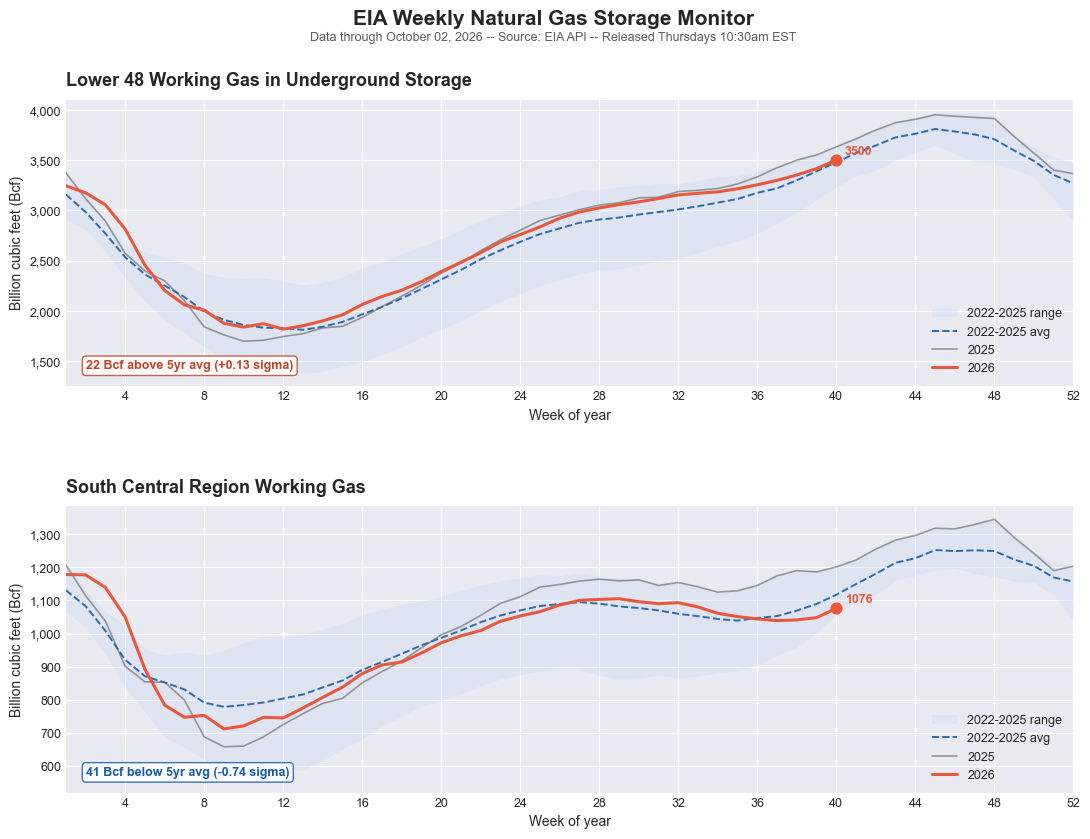


 Chart saved -> c:\Users\mackt\Python Projects\oil_gas_tools\charts\gas_storage_monitor_October_02_2026.png


In [6]:
# ============================================================
# CELL 6 — Plot: gas storage vs 5-year seasonal range
# ============================================================
# Two-panel chart:
#   Top    : Lower 48 total working gas
#   Bottom : South Central region
#
# Each panel:
#   Shaded band : 5yr min–max range
#   Dashed line : 5yr seasonal mean
#   Solid gray  : prior year
#   Bold coral  : current year
#   Dot         : most recent data point
#   Box         : deviation from mean in Bcf and sigma
# ─────────────────────────────────────────────────────────────

def plot_gas_panel(
        ax,
        seasonal: pd.DataFrame,
        df_curr: pd.DataFrame,
        value_col: str,
        title: str,
        ylabel: str,
        current_year: int,
        prior_year: int,
        color_current: str = "#E8593C",
        color_prior: str = "#5F5E5A",
        color_mean: str = "#185FA5",
        color_band: str = "#BfD4F4"
):
    """
    Plot one gas storage panel onto the given Axes object.
    Reusable for Lower 48 total and South Central panels.
    """

    weeks = seasonal["week_id"].values

    # ── Shaded min–max band ───────────────────────────────────
    ax.fill_between(
        weeks,
        seasonal["min"],
        seasonal["max"],
        alpha = 0.25,
        color = color_band,
        label = f"{prior_year - 3}-{prior_year} range",
        linewidth = 0,
    )

    # ── Seasonal mean line ────────────────────────────────────
    ax.plot(
        weeks,
        seasonal["mean"],
        color = color_mean,
        linewidth = 1.4,
        linestyle = "--",
        alpha = 0.9,
        label = f"{prior_year - 3}-{prior_year} avg",
    )

    # ── Prior year line ───────────────────────────────────────
    ax.plot(
        weeks,
        seasonal["prior_yr"],
        color = color_prior,
        linewidth = 1.2,
        linestyle = "-",
        alpha = 0.6,
        label = str(prior_year),
        zorder = 4,
    )

    # ── Current year line ─────────────────────────────────────
    ax.plot(
        df_curr["week_id"],
        df_curr[value_col],
        color = color_current,
        linewidth = 2.2,
        linestyle = "-",
        label = str(current_year),
        zorder = 5,
    )

    # ── Most recent data point dot ────────────────────────────
    latest = df_curr.iloc[-1]
    ax.scatter(
        latest["week_id"],
        latest[value_col],
        color = color_current,
        s = 60,
        zorder = 6,
    )

    # ── Annotate latest value ─────────────────────────────────
    ax.annotate(
        f"{latest[value_col]:.0f}",
        xy = (latest["week_id"], latest[value_col]),
        xytext = (6, 4),
        textcoords = "offset points",
        fontsize = 9,
        color = color_current,
        fontweight = "bold",
    )

    # ── Deviation annotation box ──────────────────────────────
    dev_bcf = latest[value_col] - latest["mean"]
    dev_std = dev_bcf / latest["std"]
    direction = "above" if dev_bcf >= 0 else "below"
    box_color = "#c04828" if dev_bcf >= 0 else "#185FA5"

    ax.text(
        0.02, 0.06,
        f"{abs(dev_bcf):.0f} Bcf {direction} 5yr avg "
        f"({dev_std:+.2f} sigma)",
        transform = ax.transAxes,
        fontsize = 9,
        color = box_color,
        fontweight = "bold",
        bbox = dict(boxstyle = "round, pad=0.3",
                    facecolor = "white",
                    edgecolor = box_color,
                    alpha = 0.85),
    )

    # ── Axes formatting ───────────────────────────────────────
    ax.set_title(title, fontsize=13, fontweight="bold",
                 pad=10, loc="left")
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xlabel("Week of year", fontsize=10)
    ax.set_xlim(1, 52)
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
    )
    ax.xaxis.set_major_locator(mticker.MultipleLocator(4))
    ax.xaxis.set_minor_locator(mticker.MultipleLocator(1))
    ax.tick_params(axis="both", labelsize=9)
    ax.legend(fontsize=9, loc="lower right",
              framealpha=0.85, edgecolor="none")
    
    return ax

# ── Build the figure ──────────────────────────────────────────
CURRENT_YEAR = df_current["year"].max()

fig, axes = plt.subplots(
    2, 1,
    figsize = (13, 9),
    sharex = False,
    gridspec_kw = {"hspace": 0.42},
)

# Top panel — Lower 48 total
plot_gas_panel(
    ax = axes[0],
    seasonal = seasonal_us,
    df_curr = df_current_us,
    value_col = "us_total",
    title = "Lower 48 Working Gas in Underground Storage",
    ylabel = "Billion cubic feet (Bcf)",
    current_year = CURRENT_YEAR,
    prior_year = prior_yr_us,
)

# Bottom panel — South Central
plot_gas_panel(
    ax           = axes[1],
    seasonal     = seasonal_sc,
    df_curr      = df_current_sc,
    value_col    = "south_total",
    title        = "South Central Region Working Gas",
    ylabel       = "Billion cubic feet (Bcf)",
    current_year = CURRENT_YEAR,
    prior_year   = prior_yr_sc,
)

# ── Figure-level annotations ──────────────────────────────────
latest_date = df_current["date"].max().strftime("%B %d, %Y")

fig.suptitle(
    "EIA Weekly Natural Gas Storage Monitor",
    fontsize = 15,
    fontweight = "bold",
    y = 0.98,
)
fig.text(
    0.5, 0.945,
    f"Data through {latest_date} -- Source: EIA API -- "
    f"Released Thursdays 10:30am EST",
    ha = "center",
    fontsize = 9,
    color = "#5F5E5A"
)

# ── Save and show ─────────────────────────────────────────────
chart_name = (
    f"gas_storage_monitor_"
    f"{latest_date.replace(' ', '_').replace(',', '')}.png"
)
chart_path = CHART_DIR / chart_name
plt.savefig(chart_path, dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()

print(f"\n Chart saved -> {chart_path}")

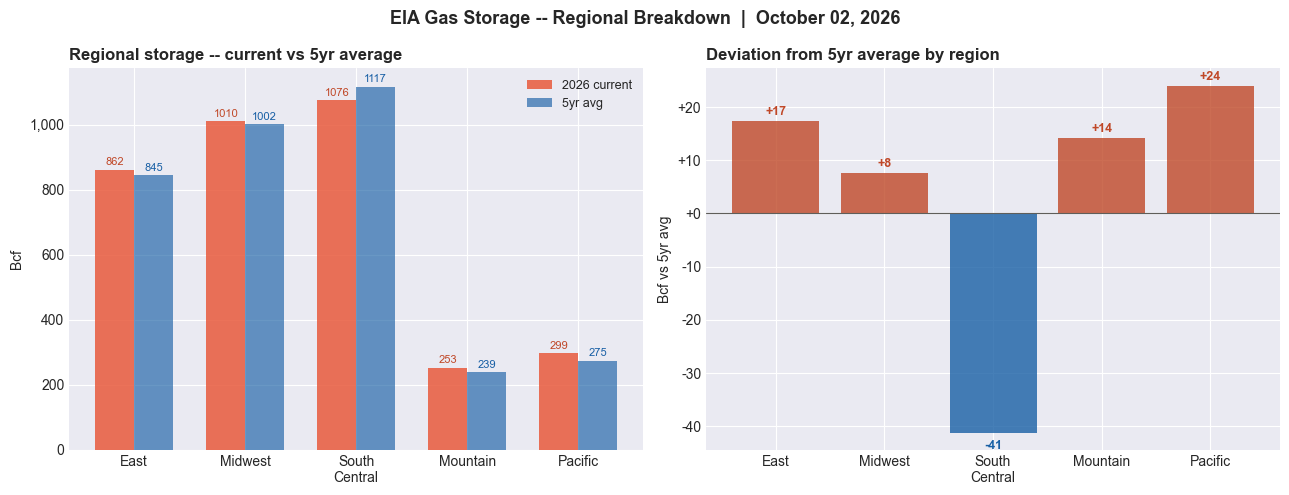


 Chart saved -> c:\Users\mackt\Python Projects\oil_gas_tools\charts\gas_storage_regional_October_02_2026.png


In [7]:
# ============================================================
# CELL 7 — Regional breakdown bar chart
# ============================================================
# Left panel  : current storage vs 5yr average per region
# Right panel : deviation from 5yr average per region (Bcf)
# Useful for spotting where surpluses/deficits are
# concentrated geographically within the national total.
# ─────────────────────────────────────────────────────────────

# ── Build per-region stats for the latest week ────────────────
region_display = {
    "east" : "East",
    "midwest": "Midwest",
    "south_total" : "South\nCentral",
    "mountain" : "Mountain",
    "pacific" : "Pacific"
}

latest_full = df_current.iloc[-1]
current_week = int(latest_full["week_id"])

labels = []
curr_vals = []
avg_vals = []
dev_vals = []

for col, label in region_display.items():
    # Historical average for this specific week of the year
    hist_week = df_history[
        df_history["week_id"] == current_week
    ][col].dropna()

    avg = hist_week.mean() if len(hist_week) > 0 else np.nan
    curr = float(latest_full[col]) if col in latest_full.index else np.nan
    dev = (curr - avg
           if not np.isnan(curr) and not np.isnan(avg)
           else np.nan)
    
    labels.append(label)
    curr_vals.append(curr)
    avg_vals.append(avg)
    dev_vals.append(dev)

# ── Build figure ──────────────────────────────────────────────
x = np.arange(len(labels))
w = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (13, 5))

# ── Left: current vs 5yr average ─────────────────────────────
bars_curr = ax1.bar(x - w/2, curr_vals, w,
                    label=f"{CURRENT_YEAR} current",
                    color="#E8593C", alpha=0.85)
bars_avg = ax1.bar(x + w/2, avg_vals, w,
                   label="5yr avg",
                   color="#185FA5", alpha = 0.65)

ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=10)
ax1.set_ylabel("Bcf", fontsize=10)
ax1.set_title("Regional storage -- current vs 5yr average",
              fontsize=12, fontweight="bold", loc="left")
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, _: f"{v:,.0f}")
)
ax1.legend(fontsize=9)

# Annotate current value on top of each current bar
for bar in bars_curr:
    h = bar.get_height()
    if not np.isnan(h):
        ax1.annotate(
            f"{h:.0f}",
            xy = (bar.get_x() + bar.get_width() / 2, h),
            xytext = (0, 3),
            textcoords = "offset points",
            ha = "center",
            fontsize = 8,
            color = "#c04828",
        )

# Annotate avg value on top of each avg bar
for bar in bars_avg:
    h = bar.get_height()
    if not np.isnan(h):
        ax1.annotate(
            f"{h:.0f}",
            xy = (bar.get_x() + bar.get_width() / 2, h),
            xytext = (0, 3),
            textcoords = "offset points",
            ha = "center",
            fontsize = 8,
            color = "#185FA5",
        )

# ── Right: deviation from 5yr average ────────────────────────
colors_dev = [
    "#c04828" if (not np.isnan(d) and d >= 0) else "#185FA5"
    for d in dev_vals
]

ax2.bar(x, dev_vals, color=colors_dev, alpha=0.8)
ax2.axhline(0, color="#5F5E5A", linewidth=0.8)

ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel("Bcf vs 5yr avg", fontsize=10)
ax2.set_title("Deviation from 5yr average by region",
              fontsize=12, fontweight="bold", loc="left")
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, _: f"{v:+.0f}")
)

# Annotate deviation value above/below each bar
for i, d in enumerate(dev_vals):
    if not np.isnan(d):
        ax2.annotate(
            f"{d:+.0f}",
            xy = (i, d),
            xytext = (0, 4 if d>= 0 else -12),
            textcoords = "offset points",
            ha = "center",
            fontsize = 9,
            color = colors_dev[i],
            fontweight = "bold",
        )

# ── Figure-level title ────────────────────────────────────────
fig.suptitle(
    f"EIA Gas Storage -- Regional Breakdown  |  {latest_date}",
    fontsize = 13,
    fontweight = "bold",
)
plt.tight_layout()

chart_name2 = (
    f"gas_storage_regional_"
    f"{latest_date.replace(' ', '_').replace(',', '')}.png"
)
chart_path2 = CHART_DIR / chart_name2
plt.savefig(chart_path2, dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()

print(f"\n Chart saved -> {chart_path2}")


In [8]:
# ============================================================
# CELL 8 — Signal dashboard and plain English summary
# ============================================================
# Calculates percentile rank, WoW change,
# YoY comparison, and injection season pace.
# Prints a plain English paragraph for a morning note.
#
# Signal direction (gas is same logic as crude):
#   Below average storage -> tighter supply cushion
#   -> BULLISH for Henry Hub prices
#   Above average storage -> ample supply cushion
#   -> BEARISH for Henry Hub prices
# ─────────────────────────────────────────────────────────────

latest_us   = df_current_us.iloc[-1]
latest_sc   = df_current_sc.iloc[-1]
latest_date = df_current["date"].max().strftime("%B %d, %Y")
current_week = int(latest_us["week_id"])

# ── Deviations ────────────────────────────────────────────────
us_dev_bcf  = float(latest_us["dev_bcf"])
us_dev_std  = float(latest_us["dev_std"])
sc_dev_bcf  = float(latest_sc["dev_bcf"])
sc_dev_std  = float(latest_sc["dev_std"])


def classify_signal(z: float):
    """
    Convert z-score to direction + strength labels.
    Negative z -> below average -> BULLISH for Henry Hub.
    Positive z -> above average -> BEARISH for Henry Hub.
    """
    abs_z = abs(z)
    if abs_z < 0.5:
        return "NEUTRAL", ""
    direction = "BULLISH" if z < 0 else "BEARISH"
    if abs_z < 1.0:
        strength = "mild"
    elif abs_z < 1.5:
        strength = "moderate"
    elif abs_z < 2.0:
        strength = "strong"
    else:
        strength = "EXTREME"
    return direction, strength

us_direction, us_strength     = classify_signal(us_dev_std)
sc_direction, sc_strength     = classify_signal(sc_dev_std)

# ── Percentile rank — uses extended history ───────────────────
# With 10yr window: ~9 prior-year points per week
# vs 4 points with 5yr window
# Percentile steps of ~11% vs 25% — meaningfully finer

hist_us_week_pctile = df_us_pctile_hist[
    df_us_pctile_hist["week_id"] == current_week
]["us_total"].values

hist_sc_week_pctile = df_sc_pctile_hist[
    df_sc_pctile_hist["week_id"] == current_week
]["south_total"].values

us_pctile = (
    (hist_us_week_pctile < latest_us["us_total"]).sum()
    / len(hist_us_week_pctile) * 100
    if len(hist_us_week_pctile) > 0 else float("nan")
)
sc_pctile = (
    (hist_sc_week_pctile < latest_sc["south_total"]).sum()
    / len(hist_sc_week_pctile) * 100
    if len(hist_sc_week_pctile) > 0 else float("nan")
)

n_us_pts   = len(hist_us_week_pctile)
n_sc_pts   = len(hist_sc_week_pctile)

# ── Week-on-week change ───────────────────────────────────────
if len(df_current_us) >= 2:
    us_wow = (df_current_us.iloc[-1]["us_total"]
              - df_current_us.iloc[-2]["us_total"])
    sc_wow = (df_current_sc.iloc[-1]["south_total"]
              - df_current_sc.iloc[-2]["south_total"])
else:
    us_wow = sc_wow = float("nan")

# Positive WoW = injection (refilling)
# Negative WoW = withdrawal (drawing down)
wow_dir_us = "injection" if us_wow >= 0 else "withdrawal"
wow_dir_sc = "injection" if sc_wow >= 0 else "withdrawal"

# ── Year-on-year comparison ───────────────────────────────────
prior_us_week = df_history[
    (df_history["week_id"] == current_week) &
    (df_history["year"] == prior_yr_us)
]["us_total"].values

prior_sc_week = df_history[
    (df_history["week_id"] == current_week) &
    (df_history["year"] == prior_yr_us)
]["south_total"].values

us_yoy = (
    float(latest_us["us_total"]) - float(prior_us_week[0])
    if len(prior_us_week) > 0 else float("nan")
)
sc_yoy = (
    float(latest_sc["south_total"]) - float(prior_sc_week[0])
    if len(prior_sc_week) > 0 else float("nan")
)

us_yoy_dir = "above" if us_yoy >= 0 else "below"
sc_yoy_dir = "above" if sc_yoy >= 0 else "below"


# ── Injection season pace tracker ─────────────────────────────
# Injection season: approximately April (week 14) to October
# (week 44). We look at how much has been injected so far
# this season vs the historical average pace.
# In early spring we may not yet be in injection season —
# we handle that gracefully.

inj_season_start_week = 14  # approximate start of injection

if current_week >= inj_season_start_week:
    # Current year injection so far
    curr_inj_rows = df_current_us[
        df_current_us["week_id"] >= inj_season_start_week
    ]
    if len(curr_inj_rows) >= 2:
        curr_inj_bcf = (
            curr_inj_rows["us_total"].iloc[-1]
            - curr_inj_rows["us_total"].iloc[0]
        )
        curr_inj_weeks = len(curr_inj_rows) - 1
        curr_pace = curr_inj_bcf / curr_inj_weeks

        # Historical avg injection pace for same weeks
        hist_inj = df_history[
            df_history["week_id"] >= inj_season_start_week
        ]
        hist_pace = (
            hist_inj.groupby("year")["us_total"]
            .apply(lambda s: (s.iloc[-1] - s.iloc[0])
                   / max(len(s) - 1, 1))
            .mean()
        )
        pace_note = (
            f"{curr_pace:+.1f} Bcf/wk this season vs "
            f"{hist_pace:.1f} Bcf/wk historical avg"
        )
    else:
        pace_note = "Injection season just started — insufficient weeks"
else:
    pace_note = (
        f"Injection season not yet started "
        f"(begins ~week {inj_season_start_week})"
    )

# ── Signal dashboard ──────────────────────────────────────────
print("=" * 62)
print("EIA NATURAL GAS STORAGE SIGNAL DASHBOARD")
print(f"Data through {latest_date}")
print("=" * 62)

print(f"""
  --SIGNAL SUMMARY--

  LOWER 48 TOTAL WORKING GAS
  {'─' * 48}
  Current level    : {latest_us['us_total']:>8.0f} Bcf
  5yr seasonal avg : {latest_us['mean']:>8.0f} Bcf
  Deviation        : {us_dev_bcf:>+8.0f} Bcf  ({us_dev_std:+.2f} sigma)
  vs prior year    : {us_yoy:>+8.0f} Bcf  ({us_yoy_dir} {prior_yr_us})
  Week-on-week     : {us_wow:>+8.0f} Bcf  ({wow_dir_us})
  Percentile       : {us_pctile:>8.0f}  ({YEARS_PERCENTILE}yr window, {n_us_pts} obs)
  Signal           :  {us_strength} {us_direction}

  SOUTH CENTRAL REGION
  {'─' * 48}
  Current level    : {latest_sc['south_total']:>8.0f} Bcf
  5yr seasonal avg : {latest_sc['mean']:>8.0f} Bcf
  Deviation        : {sc_dev_bcf:>+8.0f} Bcf  ({sc_dev_std:+.2f} sigma)
  vs prior year    : {sc_yoy:>+8.0f} Bcf  ({sc_yoy_dir} {prior_yr_us})
  Week-on-week     : {sc_wow:>+8.0f} Bcf  ({wow_dir_sc})
  Percentile       : {sc_pctile:>8.0f}  ({YEARS_PERCENTILE}yr window, {n_sc_pts} obs)
  Signal           :  {sc_strength} {sc_direction}

  INJECTION SEASON PACE
  {'─' * 48}
  {pace_note}
""")

# ── Plain English summary ─────────────────────────────────────
us_rel = "below" if us_dev_bcf < 0 else "above"
sc_rel = "below" if sc_dev_bcf < 0 else "above"


print("=" * 62)
print("  PLAIN ENGLISH SUMMARY")
print("=" * 62)
print(f"""
  As of {latest_date}, Lower 48 working gas in underground
  storage stood at {latest_us['us_total']:.0f} Bcf —
  {abs(us_dev_bcf):.0f} Bcf {us_rel} the five-year seasonal
  average of {latest_us['mean']:.0f} Bcf, at the {us_pctile:.0f}th
  percentile of the historical range for this week.
  The most recent week showed a {abs(us_wow):.0f} Bcf {wow_dir_us}.
  Year-on-year, storage is {abs(us_yoy):.0f} Bcf {us_yoy_dir}
  the same week in {prior_yr_us}.

  South Central — the region most directly connected to
  Henry Hub pricing — held {latest_sc['south_total']:.0f} Bcf,
  {abs(sc_dev_bcf):.0f} Bcf {sc_rel} its seasonal average
  ({sc_dev_std:+.2f} sigma), at the {sc_pctile:.0f}th percentile.

""")
print("=" * 62)

EIA NATURAL GAS STORAGE SIGNAL DASHBOARD
Data through October 02, 2026

  --SIGNAL SUMMARY--

  LOWER 48 TOTAL WORKING GAS
  ────────────────────────────────────────────────
  Current level    :     3500 Bcf
  5yr seasonal avg :     3478 Bcf
  Deviation        :      +22 Bcf  (+0.13 sigma)
  vs prior year    :     -131 Bcf  (below 2025)
  Week-on-week     :      +85 Bcf  (injection)
  Percentile       :       40  (10yr window, 10 obs)
  Signal           :   NEUTRAL

  SOUTH CENTRAL REGION
  ────────────────────────────────────────────────
  Current level    :     1076 Bcf
  5yr seasonal avg :     1117 Bcf
  Deviation        :      -41 Bcf  (-0.74 sigma)
  vs prior year    :     -125 Bcf  (below 2025)
  Week-on-week     :      +28 Bcf  (injection)
  Percentile       :       30  (10yr window, 10 obs)
  Signal           :  mild BULLISH

  INJECTION SEASON PACE
  ────────────────────────────────────────────────
  +61.5 Bcf/wk this season vs 31.9 Bcf/wk historical avg

  PLAIN ENGLISH SUMMA

In [9]:
# ============================================================
# CELL 9 — Save data and wrap up
# ============================================================
# Saves current-year storage data with seasonal context
# to CSV in the data/ directory.
# Prints next EIA release date and series reference.
# ─────────────────────────────────────────────────────────────

# ── Build save DataFrame ──────────────────────────────────────
# Merge the seasonal context columns onto current year data
# so the CSV is self-contained for offline reference

df_save = df_current_us[[
    "date", "week_id", "us_total",
    "mean", "min", "max", "std",
    "dev_bcf", "dev_std"
]].copy()

df_save = df_save.merge(
    df_current_sc[[
        "date", "south_total",
        "dev_bcf", "dev_std"
    ]].rename(columns={
        "dev_bcf" : "sc_dev_bcf",
        "dev_std" : "sc_dev_std",
    }),
    on  = "date",
    how = "left",
)

# Add the other regions from df_current for completeness
df_save = df_save.merge(
    df_current[["date", "east", "midwest", "mountain", "pacific"]],
    on  = "date",
    how = "left",
)

# ── Save to CSV ───────────────────────────────────────────────
csv_filename = (
    f"gas_storage_"
    f"{latest_date.replace(' ', '_').replace(',', '')}.csv"
)
csv_path = DATA_DIR / csv_filename
df_save.to_csv(csv_path, index=False)
print(f"  Data saved -> {csv_path}")

# ── Save weekly commentary log ────────────────────────────────
commentary_path = DATA_DIR / "gas_storage_commentary_log.txt"

price_bias_note = (
    "BULLISH for Henry Hub"  if us_dev_std < -0.5
    else "BEARISH for Henry Hub" if us_dev_std >  0.5
    else "NEUTRAL for Henry Hub"
)

commentary_entry = f"""
{'=' * 62}
EIA NATURAL GAS STORAGE COMMENTARY
Run date  : {dt.date.today().strftime('%B %d, %Y')}
Data date : {latest_date}
{'=' * 62}

METRICS SNAPSHOT
  Lower 48 total   : {latest_us['us_total']:.0f} Bcf
  vs 5yr avg       : {us_dev_bcf:+.0f} Bcf ({us_dev_std:+.2f} sigma)
  L48 WoW          : {us_wow:+.0f} Bcf ({wow_dir_us})
  L48 YoY          : {us_yoy:+.0f} Bcf ({us_yoy_dir} {prior_yr_us})
  L48 percentile   : {us_pctile:.0f} ({YEARS_PERCENTILE}yr window, {n_us_pts} obs)
  L48 signal       : {us_strength} {us_direction}

  South Central    : {latest_sc['south_total']:.0f} Bcf
  vs 5yr avg       : {sc_dev_bcf:+.0f} Bcf ({sc_dev_std:+.2f} sigma)
  SC WoW           : {sc_wow:+.0f} Bcf ({wow_dir_sc})
  SC YoY           : {sc_yoy:+.0f} Bcf ({sc_yoy_dir} {prior_yr_us})
  SC percentile    : {sc_pctile:.0f} ({YEARS_PERCENTILE}yr window, {n_sc_pts} obs)
  SC signal        : {sc_strength} {sc_direction}

  Injection pace   : {pace_note}
  Price bias       : {price_bias_note}

PLAIN ENGLISH SUMMARY
  As of {latest_date}, Lower 48 working gas in underground
  storage stood at {latest_us['us_total']:.0f} Bcf —
  {abs(us_dev_bcf):.0f} Bcf {us_rel} the five-year seasonal
  average of {latest_us['mean']:.0f} Bcf, at the {us_pctile:.0f}
  percentile of the historical range for this week.
  The most recent week showed a {abs(us_wow):.0f} Bcf {wow_dir_us}.
  Year-on-year, storage is {abs(us_yoy):.0f} Bcf {us_yoy_dir}
  the same week in {prior_yr_us}.

  South Central held {latest_sc['south_total']:.0f} Bcf,
  {abs(sc_dev_bcf):.0f} Bcf {sc_rel} its seasonal average
  ({sc_dev_std:+.2f} sigma), at the {sc_pctile:.0f} percentile.
  Injection pace: {pace_note}.
  Price bias: {price_bias_note}.

"""

with open(commentary_path, "a", encoding="utf-8") as f:
    f.write(commentary_entry)

print(f"  Commentary logged -> {commentary_path.name}")

# ── Next release reminder ─────────────────────────────────────
today = dt.date.today()
days_to_thursday = (3 - today.weekday()) % 7
if days_to_thursday == 0:
    next_thursday = today
else:
    next_thursday = today + dt.timedelta(days=days_to_thursday)

print(f"  Next EIA storage release -> "
      f"Thursday {next_thursday} at 10:30am ET")

# ── Notebook summary ──────────────────────────────────────────
print()
print("=" * 62)
print("  TOOL 3 COMPLETE — Natural Gas Storage Tracker")
print("=" * 62)
print(f"""
  What this notebook built:
  {'─' * 54}
  Pulled {len(df)} weeks of EIA gas storage data (6 regions)
  Validated data quality and physical plausibility ranges
  Built {YEARS_HISTORY}-year seasonal range by week of year
  Calculated z-score deviations from seasonal average
  Plotted Lower 48 + South Central vs seasonal range
  Regional breakdown chart (current vs avg + deviation)
  Signal dashboard with injection season pace tracker
  Plain English morning-note summary

  To refresh after next Thursday's EIA release:
  {'─' * 54}
  1. Kernel -> Restart Kernel and Run All Cells
  2. New chart and signal auto-save with today's date
  3. Check dashboard for updated z-scores and pace

  EIA series reference (verified April 2026):
  {'─' * 54}
  Route   : /natural-gas/stor/wkly/data/
  Process : SWO (total working gas — formerly SAT)

  duoarea codes (updated — EIA changed these in 2025/26):
  R48  = Lower 48 States   (formerly NUS)
  R31  = East              (formerly R30)
  R32  = Midwest           (formerly R20)
  R33  = South Central     (formerly R10)
  R34  = Mountain          (formerly R40)
  R35  = Pacific           (formerly R50)

  Note: Salt cavern (SL10) and nonsalt (SN10) sub-series
  no longer available at this endpoint as of April 2026.

  Workflow with other tools:
  {'─' * 54}
  Run Tool 3 on Thursdays after 10:30am ET
  South Central signal feeds directly into Tool 5
  (LNG export monitor) as the Henry Hub price context
""")
print("=" * 62)

  Data saved -> c:\Users\mackt\Python Projects\oil_gas_tools\data\gas_storage_October_02_2026.csv
  Commentary logged -> gas_storage_commentary_log.txt
  Next EIA storage release -> Thursday 2026-10-15 at 10:30am ET

  TOOL 3 COMPLETE — Natural Gas Storage Tracker

  What this notebook built:
  ──────────────────────────────────────────────────────
  Pulled 264 weeks of EIA gas storage data (6 regions)
  Validated data quality and physical plausibility ranges
  Built 5-year seasonal range by week of year
  Calculated z-score deviations from seasonal average
  Plotted Lower 48 + South Central vs seasonal range
  Regional breakdown chart (current vs avg + deviation)
  Signal dashboard with injection season pace tracker
  Plain English morning-note summary

  To refresh after next Thursday's EIA release:
  ──────────────────────────────────────────────────────
  1. Kernel -> Restart Kernel and Run All Cells
  2. New chart and signal auto-save with today's date
  3. Check dashboard for upd